# Diabetes Patients Classification

A complete classification workflow for predicting diabetes status.

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

## 2. Load Dataset

In [3]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\my_projects\Project diabetes patients\diabetes_patients_10000_full.csv")

display(df.head())
print("Dataset shape:", df.shape)

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


Dataset shape: (10000, 10)


## 3. Initial Inspection

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   str    
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  str    
dtypes: float64(7), int64(1), str(2)
memory usage: 781.4 KB


In [5]:
display(df.isnull().sum().to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())
display(df["Class"].value_counts())

,Missing Values
Patient_ID,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


Duplicate rows: 0


Class
Diabetic        9146
Non-Diabetic     854
Name: count, dtype: int64

## 4. Data Cleaning

In [6]:
df = df.drop_duplicates().copy()

numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()

for column in numeric_features:
    df[column] = df[column].fillna(df[column].median())

for column in categorical_features:
    if column != "Class":
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

Missing values after cleaning:


,Missing Values
Patient_ID,0
Age,0
Gender,0
Blood_Sugar_Level,0
Creatinine,0
BMI,0
Urea,0
Cholesterol,0
HbA1c,0
Class,0


## 5. Exploratory Data Analysis

In [7]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Age,10000.0,NaN,NaN,NaN,49.9573,17.61775,20.0,35.0,50.0,65.0,80.0
Gender,10000,2,Female,5067,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood_Sugar_Level,10000.0,NaN,NaN,NaN,169.2541,45.936832,90.0,130.0,169.0,208.0,250.0
Creatinine,10000.0,NaN,NaN,NaN,1.100252,0.286159,0.6,0.85,1.1,1.35,1.6
BMI,10000.0,NaN,NaN,NaN,26.74672,4.774992,18.5,22.6,26.7,30.9,35.0
Urea,10000.0,NaN,NaN,NaN,35.1209,11.79978,15.0,25.0,35.0,45.0,55.0
Cholesterol,10000.0,NaN,NaN,NaN,225.3102,43.736553,150.0,188.0,225.0,263.0,300.0
HbA1c,10000.0,NaN,NaN,NaN,7.50378,1.743745,4.5,6.0,7.5,9.0,10.5
Class,10000,2,Diabetic,9146,NaN,NaN,NaN,NaN,NaN,NaN,NaN


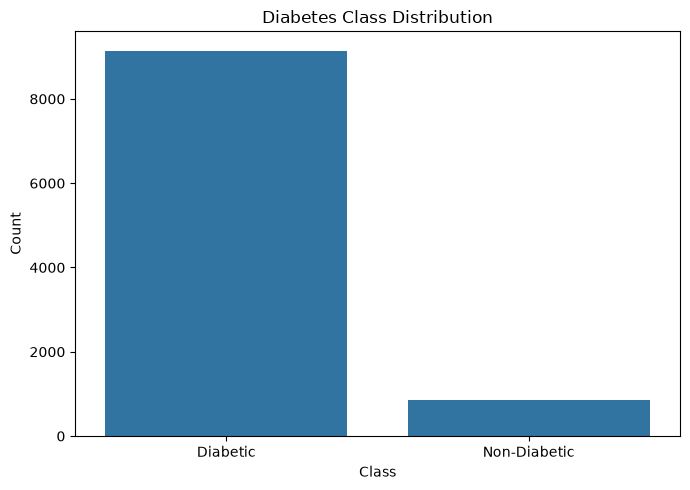

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.title("Diabetes Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

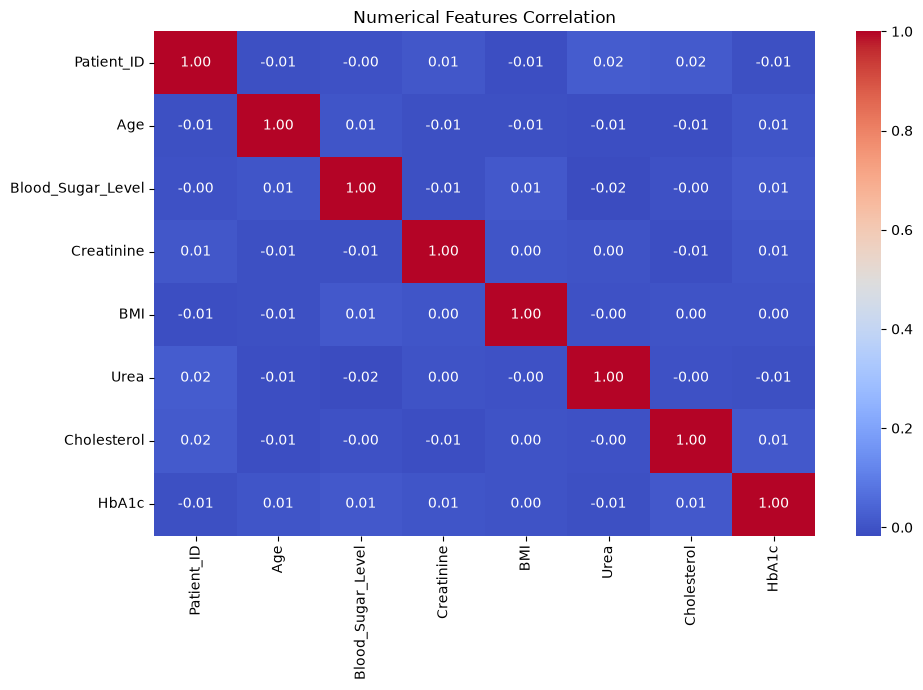

In [9]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Features Correlation")
plt.tight_layout()
plt.show()

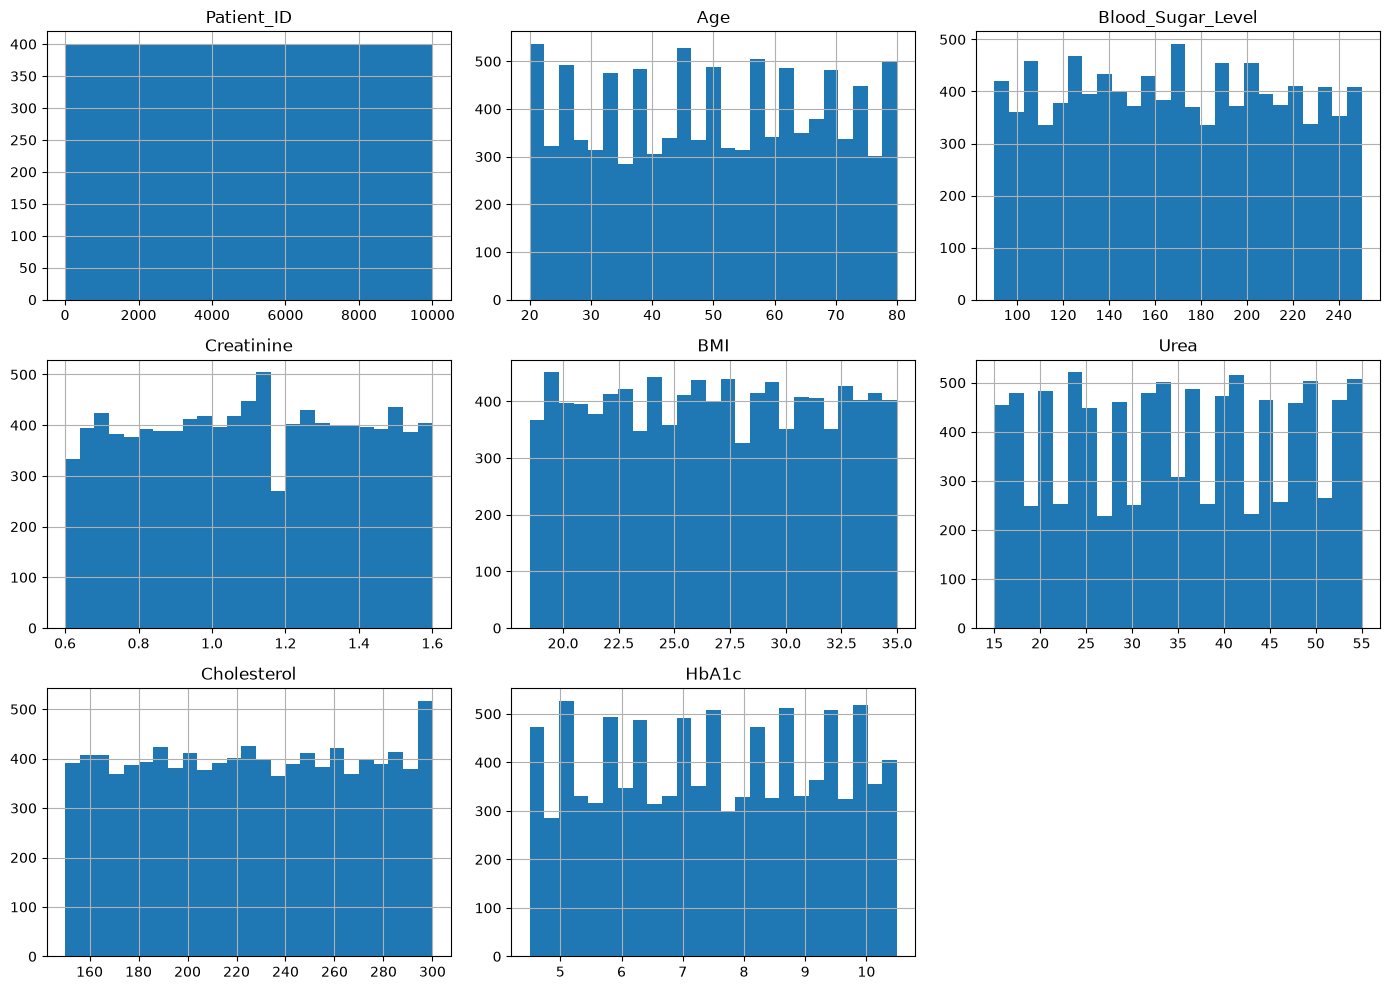

In [10]:
df.select_dtypes(include=np.number).hist(figsize=(14, 10), bins=25)
plt.tight_layout()
plt.show()

## 6. Prepare Features and Target

In [11]:
X = df.drop(columns=["Class", "Patient_ID"], errors="ignore")
target = df["Class"].astype(str).str.strip().str.lower()

target_mapping = {
    "non-diabetic": 0,
    "non diabetic": 0,
    "diabetic": 1
}

y = target.map(target_mapping)

if y.isna().any():
    unknown_classes = target[y.isna()].unique().tolist()
    raise ValueError(f"Unexpected target classes: {unknown_classes}")

y = y.astype(int)

print("Target mapping:", {"Non-Diabetic": 0, "Diabetic": 1})
print("Features shape:", X.shape)

Target mapping: {'Non-Diabetic': 0, 'Diabetic': 1}
Features shape: (10000, 8)


## 7. Train-Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (8000, 8)
Testing shape: (2000, 8)


## 8. Preprocessing

In [13]:
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features)
    ],
    remainder="drop"
)

## 9. Classification Models

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVC": SVC(kernel="linear", probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=300,
        verbose=0,
        random_state=42,
        thread_count=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

print("Number of models:", len(models))

Number of models: 13


## 10. Train and Evaluate All Models

In [15]:
results = []
trained_models = {}
failed_models = {}

for name, model in tqdm(models.items(), total=len(models)):
    try:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)

        if hasattr(pipeline, "predict_proba"):
            y_score = pipeline.predict_proba(X_test)[:, 1]
        elif hasattr(pipeline, "decision_function"):
            y_score = pipeline.decision_function(X_test)
        else:
            y_score = None

        row = {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, zero_division=0)
        }

        if y_score is not None:
            row["ROC-AUC"] = roc_auc_score(y_test, y_score)
            row["PR-AUC"] = average_precision_score(y_test, y_score)
        else:
            row["ROC-AUC"] = np.nan
            row["PR-AUC"] = np.nan

        results.append(row)
        trained_models[name] = pipeline

    except Exception as error:
        failed_models[name] = str(error)
        print(f"{name} could not be trained: {error}")

results_df = pd.DataFrame(results).sort_values(
    by="PR-AUC",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Balanced Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}"
}))

print("Successfully trained:", len(trained_models), "of", len(models))
if failed_models:
    print("Models with errors:", failed_models)

100%|██████████| 13/13 [00:08<00:00,  1.54it/s]


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Hist Gradient Boosting,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
1,AdaBoost,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
2,Gradient Boosting,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
3,Random Forest,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
4,CatBoost,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
5,XGBoost,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
6,LightGBM,0.9995,0.9971,0.9995,1.0000,0.9997,1.0000,1.0000
7,Extra Trees,0.9960,0.9793,0.9962,0.9995,0.9978,0.9998,1.0000
8,Naive Bayes,0.9855,0.9152,0.9844,1.0000,0.9921,0.9985,0.9999
9,Decision Tree,0.9995,0.9971,0.9995,1.0000,0.9997,0.9971,0.9995


Successfully trained: 13 of 13


## 11. Visualize Model Comparison

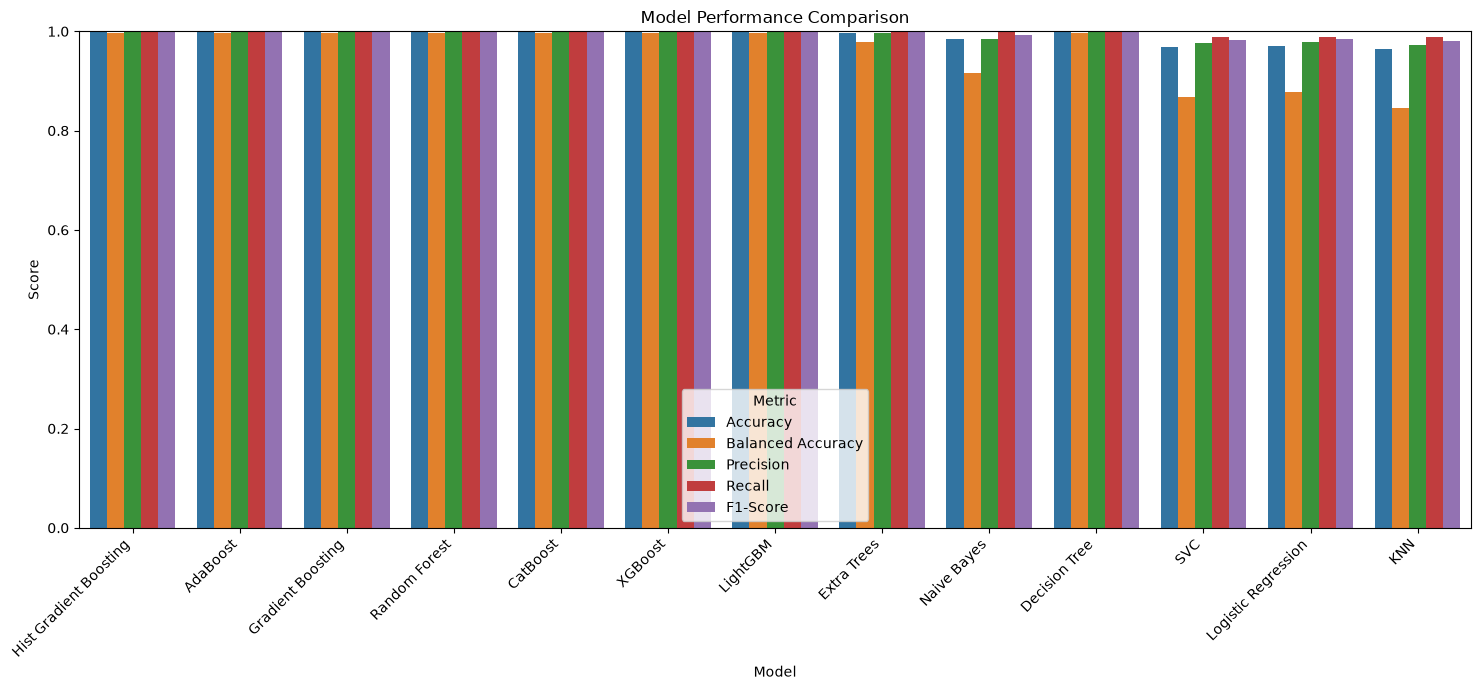

In [17]:
if not results_df.empty:
    plot_df = results_df.melt(
        id_vars="Model",
        value_vars=["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1-Score"],
        var_name="Metric",
        value_name="Score"
    )

    plt.figure(figsize=(15, 7))
    sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 1)
    plt.title("Model Performance Comparison")
    plt.tight_layout()
    plt.show()

## 12. Best Model Evaluation

In [16]:
if not results_df.empty:
    best_model_name = results_df.loc[0, "Model"]
    best_model = trained_models[best_model_name]

    best_predictions = best_model.predict(X_test)

    print("Best Model:", best_model_name)
    print(classification_report(
        y_test,
        best_predictions,
        target_names=["Non-Diabetic", "Diabetic"],
        zero_division=0
    ))

Best Model: Hist Gradient Boosting
              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



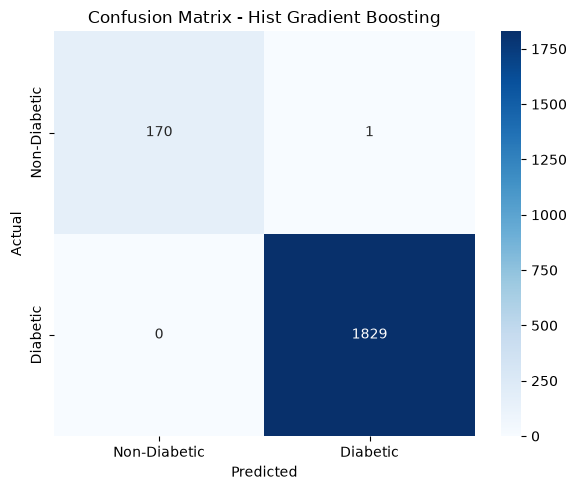

In [19]:
if not results_df.empty:
    cm = confusion_matrix(y_test, best_predictions)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Diabetic", "Diabetic"],
        yticklabels=["Non-Diabetic", "Diabetic"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.tight_layout()
    plt.show()

## 13. Save Results

In [20]:
results_df.to_csv("diabetes_model_comparison.csv", index=False)
print("Model comparison saved to diabetes_model_comparison.csv")

Model comparison saved to diabetes_model_comparison.csv
